In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision import transforms

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
print("PyTorch version:", torch.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Available device:", device)

PyTorch version: 2.14.1+cpu
Available device: cpu


In [3]:
transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [4]:
print("Training images:", len(train_dataset))

print("Testing images:", len(test_dataset))

Training images: 60000
Testing images: 10000


In [6]:
image, label = train_dataset[0]

print("Image shape:", image.shape)

print("Image label:", label)
torch.Size([1, 28, 28])

Image shape: torch.Size([1, 28, 28])
Image label: 9


torch.Size([1, 28, 28])

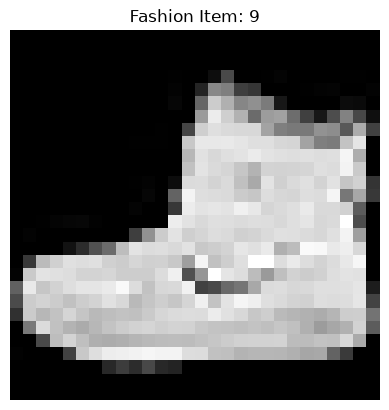

In [7]:
image, label = train_dataset[0]

plt.imshow(
    image.squeeze(),
    cmap="gray"
)

plt.title("Fashion Item: " + str(label))

plt.axis("off")

plt.show()

In [8]:
class_names = [

    "T-shirt/Top",

    "Trouser",

    "Pullover",

    "Dress",

    "Coat",

    "Sandal",

    "Shirt",

    "Sneaker",

    "Bag",

    "Ankle Boot"

]

print("Total classes:", len(class_names))

Total classes: 10


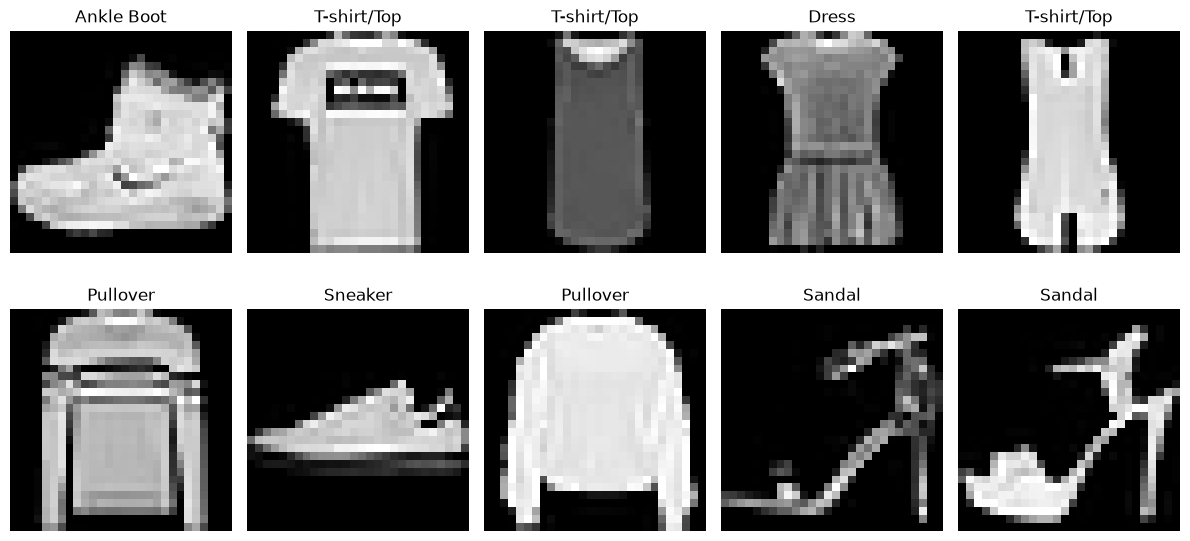

In [9]:
plt.figure(figsize=(12, 6))

for i in range(10):

    image, label = train_dataset[i]

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        image.squeeze(),
        cmap="gray"
    )

    plt.title(class_names[label])

    plt.axis("off")

plt.tight_layout()

plt.show()

In [10]:
labels = [
    train_dataset[i][1]
    for i in range(len(train_dataset))
]

class_counts = pd.Series(labels).value_counts().sort_index()

class_distribution = pd.DataFrame({

    "Class": class_names,

    "Number of Images": class_counts.values

})

class_distribution

,Class,Number of Images
0,T-shirt/Top,6000
1,Trouser,6000
2,Pullover,6000
3,Dress,6000
4,Coat,6000
5,Sandal,6000
6,Shirt,6000
7,Sneaker,6000
8,Bag,6000
9,Ankle Boot,6000


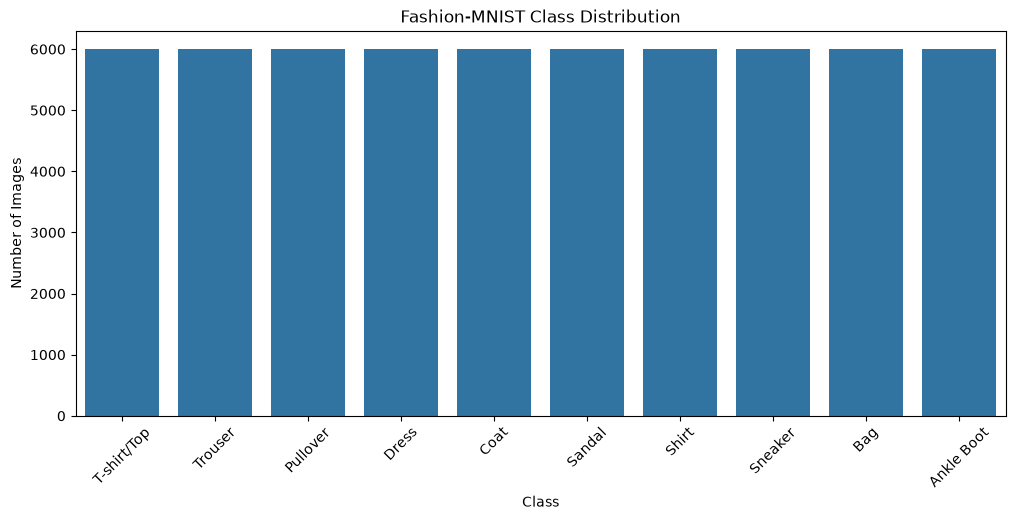

In [11]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=class_distribution,
    x="Class",
    y="Number of Images"
)

plt.title("Fashion-MNIST Class Distribution")

plt.xticks(rotation=45)

plt.show()

Image shape: (28, 28)


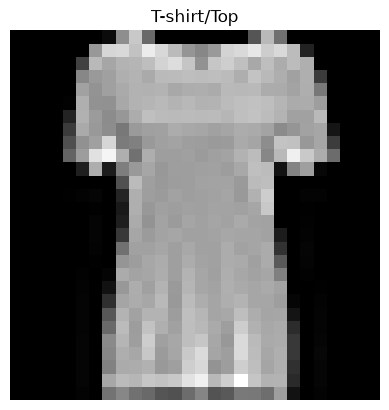

In [12]:
sample_image, sample_label = train_dataset[10]

sample_image = sample_image.squeeze().numpy()

print("Image shape:", sample_image.shape)

plt.imshow(sample_image, cmap="gray")

plt.title(class_names[sample_label])

plt.axis("off")

plt.show()

In [16]:
horizontal_filter = np.array([

    [-1, -2, -1],

    [0, 0, 0],

    [1, 2, 1]

])

print(horizontal_filter)

vertical_filter = np.array([

    [-1, 0, 1],

    [-2, 0, 2],

    [-1, 0, 1]

])
print("\n")
print(vertical_filter)
blur_filter = np.ones((3, 3)) / 9

print(blur_filter)

[[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]


[[-1  0  1]
 [-2  0  2]
 [-1  0  1]]
[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


In [17]:
def convolution_2d(image, kernel):

    image_height = image.shape[0]

    image_width = image.shape[1]

    kernel_size = kernel.shape[0]

    output_height = image_height - kernel_size + 1

    output_width = image_width - kernel_size + 1

    output = np.zeros(
        (output_height, output_width)
    )

    for i in range(output_height):

        for j in range(output_width):

            image_region = image[
                i:i + kernel_size,
                j:j + kernel_size
            ]

            output[i, j] = np.sum(
                image_region * kernel
            )

    return output

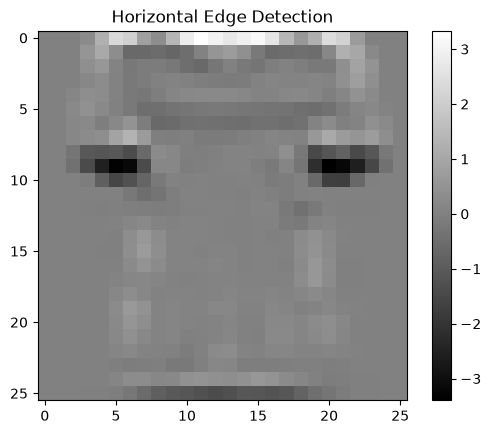

In [18]:
horizontal_output = convolution_2d(

    sample_image,

    horizontal_filter

)

plt.imshow(
    horizontal_output,
    cmap="gray"
)

plt.title("Horizontal Edge Detection")

plt.colorbar()

plt.show()

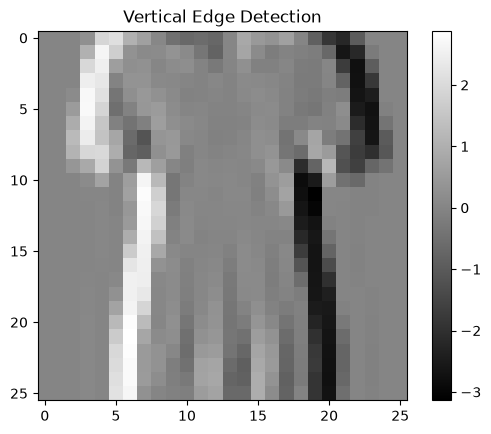

In [19]:
vertical_output = convolution_2d(

    sample_image,

    vertical_filter

)

plt.imshow(
    vertical_output,
    cmap="gray"
)

plt.title("Vertical Edge Detection")

plt.colorbar()

plt.show()

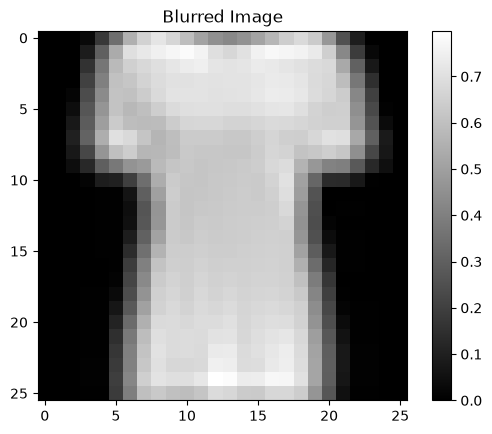

In [20]:
blur_output = convolution_2d(

    sample_image,

    blur_filter

)

plt.imshow(
    blur_output,
    cmap="gray"
)

plt.title("Blurred Image")

plt.colorbar()

plt.show()

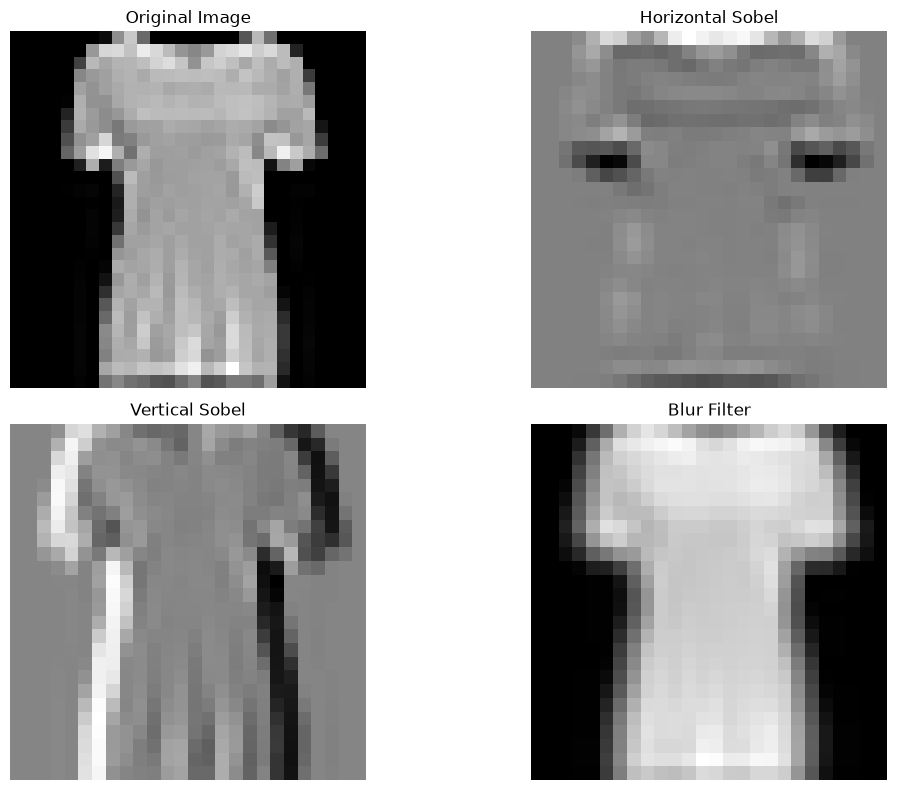

In [21]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)

plt.imshow(sample_image, cmap="gray")

plt.title("Original Image")

plt.axis("off")


plt.subplot(2, 2, 2)

plt.imshow(horizontal_output, cmap="gray")

plt.title("Horizontal Sobel")

plt.axis("off")


plt.subplot(2, 2, 3)

plt.imshow(vertical_output, cmap="gray")

plt.title("Vertical Sobel")

plt.axis("off")


plt.subplot(2, 2, 4)

plt.imshow(blur_output, cmap="gray")

plt.title("Blur Filter")

plt.axis("off")


plt.tight_layout()

plt.show()

In [22]:
input_size = 28

kernel_size = 3

padding = 0

stride = 1

output_size = (

    (input_size - kernel_size + 2 * padding)

    // stride

) + 1

print("Output height:", output_size)

print("Output width:", output_size)

Output height: 26
Output width: 26


In [23]:
feature_map = np.array([

    [1, 3, 2, 4],

    [5, 6, 1, 2],

    [7, 8, 3, 4],

    [2, 1, 5, 6]

])

print(feature_map)

[[1 3 2 4]
 [5 6 1 2]
 [7 8 3 4]
 [2 1 5 6]]


In [25]:
def max_pooling_2d(feature_map):

    height = feature_map.shape[0]

    width = feature_map.shape[1]

    output_height = height // 2

    output_width = width // 2

    output = np.zeros(
        (output_height, output_width)
    )

    for i in range(output_height):

        for j in range(output_width):

            region = feature_map[
                i*2:i*2+2,
                j*2:j*2+2
            ]

            output[i, j] = np.max(region)

    return output

In [26]:
pooled_output = max_pooling_2d(feature_map)

print("Original Feature Map:")

print(feature_map)

print("\nAfter Max Pooling:")

print(pooled_output)

Original Feature Map:
[[1 3 2 4]
 [5 6 1 2]
 [7 8 3 4]
 [2 1 5 6]]

After Max Pooling:
[[6. 4.]
 [8. 6.]]


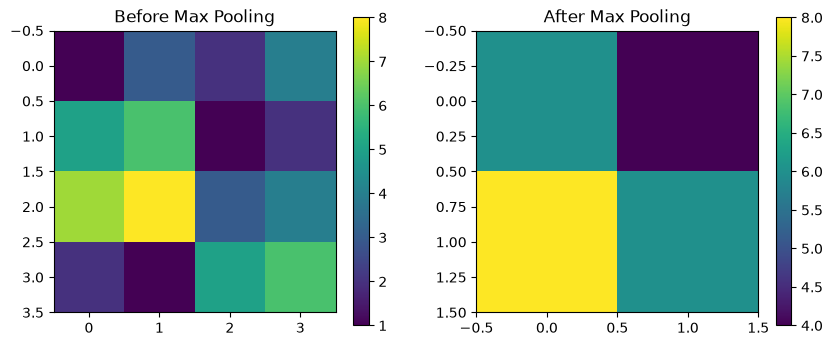

In [30]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)

plt.imshow(
    feature_map,
    cmap="viridis"
)

plt.title("Before Max Pooling")

plt.colorbar()


plt.subplot(1, 2, 2)

plt.imshow(
    pooled_output,
    cmap="viridis"
)

plt.title("After Max Pooling")

plt.colorbar()


plt.show()

In [31]:
original_height = 28

original_width = 28

pool_size = 2

pooled_height = original_height // pool_size

pooled_width = original_width // pool_size

print("Original size:", original_height, "x", original_width)

print("Pooled size:", pooled_height, "x", pooled_width)

Original size: 28 x 28
Pooled size: 14 x 14


In [32]:
from torch.utils.data import random_split

train_size = 54000

val_size = 6000

train_subset, val_subset = random_split(

    train_dataset,

    [train_size, val_size],

    generator=torch.Generator().manual_seed(42)

)

train_loader = DataLoader(

    train_subset,

    batch_size=64,

    shuffle=True

)

val_loader = DataLoader(

    val_subset,

    batch_size=64,

    shuffle=False

)

test_loader = DataLoader(

    test_dataset,

    batch_size=64,

    shuffle=False

)

print("Training batches:", len(train_loader))

print("Validation batches:", len(val_loader))

print("Testing batches:", len(test_loader))

Training batches: 844
Validation batches: 94
Testing batches: 157


In [33]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)

print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


In [35]:
class SimpleCNN(nn.Module):

    def __init__(self):

        super(SimpleCNN, self).__init__()

        self.conv1 = nn.Conv2d(

            in_channels=1,

            out_channels=32,

            kernel_size=3

        )

        self.relu = nn.ReLU()

        self.pool = nn.MaxPool2d(

            kernel_size=2,

            stride=2

        )

        self.conv2 = nn.Conv2d(

            in_channels=32,

            out_channels=64,

            kernel_size=3

        )

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(

            64 * 5 * 5,

            128

        )

        self.fc2 = nn.Linear(

            128,

            10

        )


    def forward(self, x):

        x = self.conv1(x)

        x = self.relu(x)

        x = self.pool(x)

        x = self.conv2(x)

        x = self.relu(x)

        x = self.pool(x)

        x = self.flatten(x)

        x = self.fc1(x)

        x = self.relu(x)

        x = self.fc2(x)

        return x

In [36]:
simple_model = SimpleCNN()

simple_model = simple_model.to(device)

print(simple_model)

SimpleCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1600, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [37]:
total_parameters = sum(

    parameter.numel()

    for parameter in simple_model.parameters()

)

print("Total parameters:", total_parameters)

Total parameters: 225034


In [38]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(

    simple_model.parameters(),

    lr=0.001

)

print("Loss function and optimizer created!")

Loss function and optimizer created!


In [39]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    total_loss = 0

    correct = 0

    total = 0

    for images, labels in loader:

        images = images.to(device)

        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()

        total += labels.size(0)

    average_loss = total_loss / total

    accuracy = correct / total

    return average_loss, accuracy

In [40]:
def evaluate_model(model, loader, criterion):

    model.eval()

    total_loss = 0

    correct = 0

    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

    average_loss = total_loss / total

    accuracy = correct / total

    return average_loss, accuracy

In [42]:
simple_history = {

    "train_loss": [],

    "val_loss": [],

    "train_accuracy": [],

    "val_accuracy": []

}

for epoch in range(20):

    train_loss, train_accuracy = train_one_epoch(

        simple_model,

        train_loader,

        criterion,

        optimizer

    )

    val_loss, val_accuracy = evaluate_model(

        simple_model,

        val_loader,

        criterion

    )

    simple_history["train_loss"].append(train_loss)

    simple_history["val_loss"].append(val_loss)

    simple_history["train_accuracy"].append(train_accuracy)

    simple_history["val_accuracy"].append(val_accuracy)

    print(

        f"Epoch {epoch + 1}/20 | "

        f"Train Loss: {train_loss:.4f} | "

        f"Train Accuracy: {train_accuracy:.4f} | "

        f"Val Loss: {val_loss:.4f} | "

        f"Val Accuracy: {val_accuracy:.4f}"

    )

Epoch 1/20 | Train Loss: 0.1864 | Train Accuracy: 0.9320 | Val Loss: 0.2509 | Val Accuracy: 0.9090
Epoch 2/20 | Train Loss: 0.1700 | Train Accuracy: 0.9375 | Val Loss: 0.2385 | Val Accuracy: 0.9143
Epoch 3/20 | Train Loss: 0.1549 | Train Accuracy: 0.9424 | Val Loss: 0.2476 | Val Accuracy: 0.9148
Epoch 4/20 | Train Loss: 0.1411 | Train Accuracy: 0.9477 | Val Loss: 0.2540 | Val Accuracy: 0.9147
Epoch 5/20 | Train Loss: 0.1273 | Train Accuracy: 0.9520 | Val Loss: 0.2598 | Val Accuracy: 0.9137
Epoch 6/20 | Train Loss: 0.1186 | Train Accuracy: 0.9564 | Val Loss: 0.2468 | Val Accuracy: 0.9175
Epoch 7/20 | Train Loss: 0.1063 | Train Accuracy: 0.9616 | Val Loss: 0.2625 | Val Accuracy: 0.9170
Epoch 8/20 | Train Loss: 0.0974 | Train Accuracy: 0.9641 | Val Loss: 0.2659 | Val Accuracy: 0.9137
Epoch 9/20 | Train Loss: 0.0865 | Train Accuracy: 0.9684 | Val Loss: 0.2704 | Val Accuracy: 0.9170
Epoch 10/20 | Train Loss: 0.0803 | Train Accuracy: 0.9704 | Val Loss: 0.2994 | Val Accuracy: 0.9140
Epoch 11/

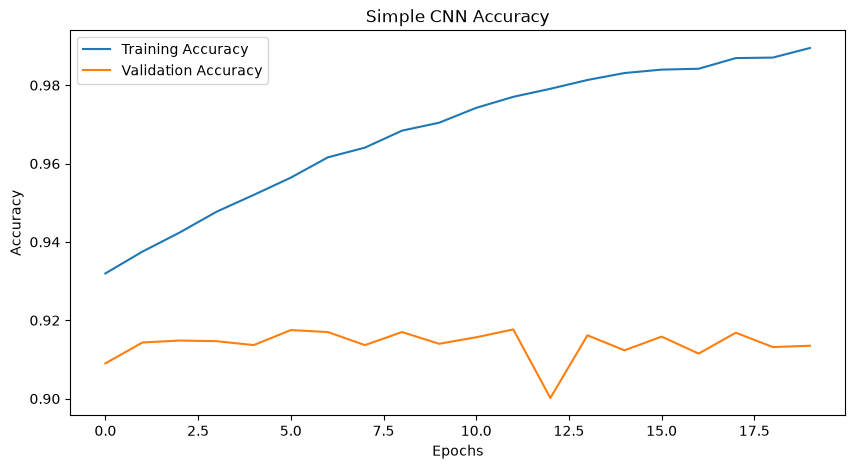

In [43]:
plt.figure(figsize=(10, 5))

plt.plot(

    simple_history["train_accuracy"],

    label="Training Accuracy"

)

plt.plot(

    simple_history["val_accuracy"],

    label="Validation Accuracy"

)

plt.title("Simple CNN Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

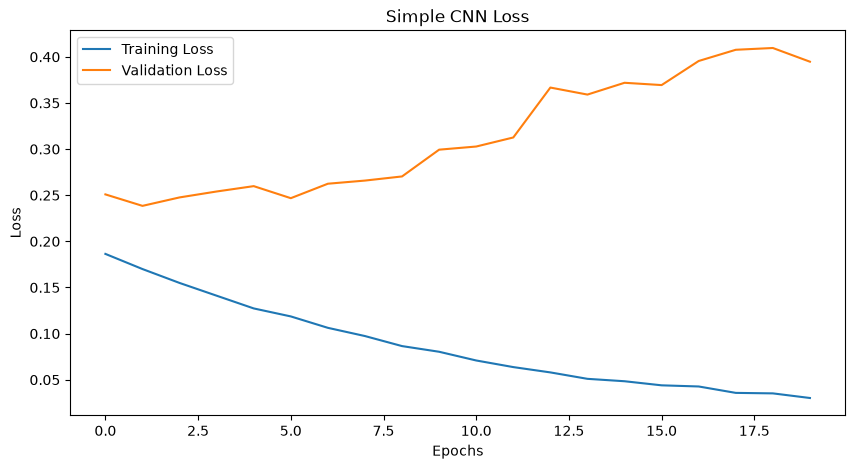

In [44]:
plt.figure(figsize=(10, 5))

plt.plot(

    simple_history["train_loss"],

    label="Training Loss"

)

plt.plot(

    simple_history["val_loss"],

    label="Validation Loss"

)

plt.title("Simple CNN Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [45]:
torch.save(

    simple_model.state_dict(),

    "fashion_cnn_checkpoint.pth"

)

print("Simple CNN checkpoint saved!")

Simple CNN checkpoint saved!


In [46]:
simple_test_loss, simple_test_accuracy = evaluate_model(

    simple_model,

    test_loader,

    criterion

)

print("Simple CNN Test Loss:", simple_test_loss)

print("Simple CNN Test Accuracy:", simple_test_accuracy)

Simple CNN Test Loss: 0.4518181740283966
Simple CNN Test Accuracy: 0.9128


In [47]:
torch.save(

    simple_model.state_dict(),

    "fashion_cnn_final.pth"

)

print("Final Simple CNN model saved!")

Final Simple CNN model saved!


In [49]:
class ImprovedCNN(nn.Module):

    def __init__(self):

        super(ImprovedCNN, self).__init__()

        self.conv1 = nn.Conv2d(

            1,

            32,

            kernel_size=3

        )

        self.bn1 = nn.BatchNorm2d(32)

        self.relu = nn.ReLU()

        self.pool = nn.MaxPool2d(2, 2)

        self.dropout_conv1 = nn.Dropout2d(0.25)


        self.conv2 = nn.Conv2d(

            32,

            64,

            kernel_size=3

        )

        self.bn2 = nn.BatchNorm2d(64)

        self.dropout_conv2 = nn.Dropout2d(0.25)


        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(

            64 * 5 * 5,

            128

        )

        self.dropout_fc = nn.Dropout(0.5)

        self.fc2 = nn.Linear(

            128,

            10

        )


    def forward(self, x):

        x = self.conv1(x)

        x = self.bn1(x)

        x = self.relu(x)

        x = self.pool(x)

        x = self.dropout_conv1(x)


        x = self.conv2(x)

        x = self.bn2(x)

        x = self.relu(x)

        x = self.pool(x)

        x = self.dropout_conv2(x)


        x = self.flatten(x)

        x = self.fc1(x)

        x = self.relu(x)

        x = self.dropout_fc(x)

        x = self.fc2(x)

        return x

In [50]:
improved_model = ImprovedCNN()

improved_model = improved_model.to(device)

print(improved_model)

ImprovedCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout_conv1): Dropout2d(p=0.25, inplace=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (dropout_conv2): Dropout2d(p=0.25, inplace=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=1600, out_features=128, bias=True)
  (dropout_fc): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [51]:
improved_parameters = sum(

    parameter.numel()

    for parameter in improved_model.parameters()

)

print("Improved CNN parameters:", improved_parameters)

Improved CNN parameters: 225226


In [52]:
improved_criterion = nn.CrossEntropyLoss()

improved_optimizer = optim.Adam(

    improved_model.parameters(),

    lr=0.001

)

print("Improved CNN optimizer ready!")

Improved CNN optimizer ready!


In [55]:
improved_history = {

    "train_loss": [],

    "val_loss": [],

    "train_accuracy": [],

    "val_accuracy": []

}

for epoch in range(20):

    train_loss, train_accuracy = train_one_epoch(

        improved_model,

        train_loader,

        improved_criterion,

        improved_optimizer

    )

    val_loss, val_accuracy = evaluate_model(

        improved_model,

        val_loader,

        improved_criterion

    )

    improved_history["train_loss"].append(train_loss)

    improved_history["val_loss"].append(val_loss)

    improved_history["train_accuracy"].append(train_accuracy)

    improved_history["val_accuracy"].append(val_accuracy)

    print(

        f"Epoch {epoch + 1}/20 | "

        f"Train Loss: {train_loss:.4f} | "

        f"Train Accuracy: {train_accuracy:.4f} | "

        f"Val Loss: {val_loss:.4f} | "

        f"Val Accuracy: {val_accuracy:.4f}"

    )

Epoch 1/20 | Train Loss: 0.4496 | Train Accuracy: 0.8359 | Val Loss: 0.3496 | Val Accuracy: 0.8720
Epoch 2/20 | Train Loss: 0.4002 | Train Accuracy: 0.8542 | Val Loss: 0.3242 | Val Accuracy: 0.8763
Epoch 3/20 | Train Loss: 0.3700 | Train Accuracy: 0.8661 | Val Loss: 0.2983 | Val Accuracy: 0.8882
Epoch 4/20 | Train Loss: 0.3446 | Train Accuracy: 0.8759 | Val Loss: 0.2859 | Val Accuracy: 0.8942
Epoch 5/20 | Train Loss: 0.3354 | Train Accuracy: 0.8790 | Val Loss: 0.2829 | Val Accuracy: 0.8972
Epoch 6/20 | Train Loss: 0.3198 | Train Accuracy: 0.8829 | Val Loss: 0.2794 | Val Accuracy: 0.8985
Epoch 7/20 | Train Loss: 0.3061 | Train Accuracy: 0.8878 | Val Loss: 0.2616 | Val Accuracy: 0.9020
Epoch 8/20 | Train Loss: 0.2989 | Train Accuracy: 0.8898 | Val Loss: 0.2577 | Val Accuracy: 0.9033
Epoch 9/20 | Train Loss: 0.2926 | Train Accuracy: 0.8929 | Val Loss: 0.2516 | Val Accuracy: 0.9077
Epoch 10/20 | Train Loss: 0.2879 | Train Accuracy: 0.8940 | Val Loss: 0.2497 | Val Accuracy: 0.9100
Epoch 11/

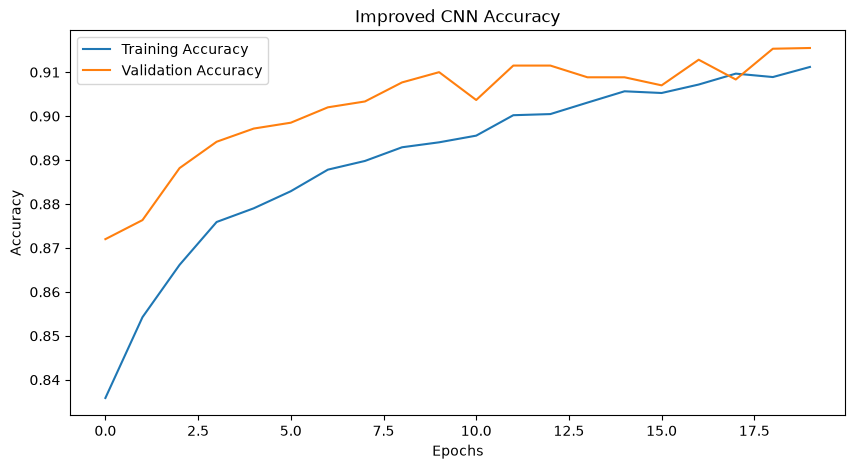

In [56]:
plt.figure(figsize=(10, 5))

plt.plot(

    improved_history["train_accuracy"],

    label="Training Accuracy"

)

plt.plot(

    improved_history["val_accuracy"],

    label="Validation Accuracy"

)

plt.title("Improved CNN Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.show()

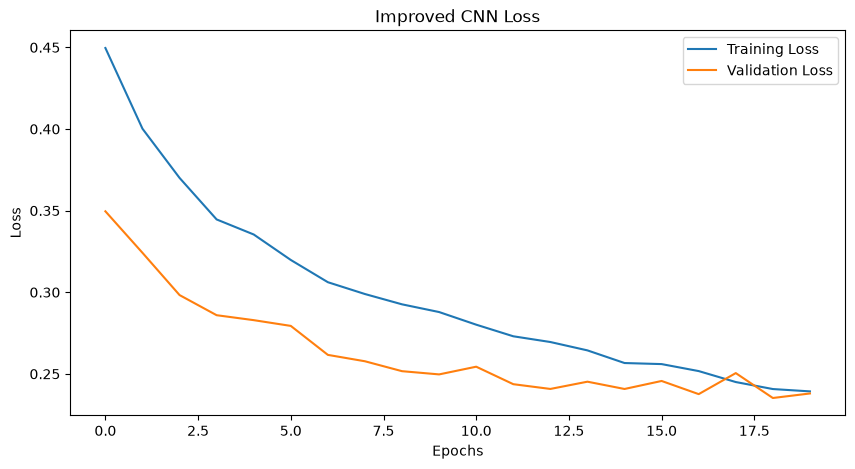

In [57]:
plt.figure(figsize=(10, 5))

plt.plot(

    improved_history["train_loss"],

    label="Training Loss"

)

plt.plot(

    improved_history["val_loss"],

    label="Validation Loss"

)

plt.title("Improved CNN Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [58]:
improved_test_loss, improved_test_accuracy = evaluate_model(

    improved_model,

    test_loader,

    improved_criterion

)

print("Improved CNN Test Loss:", improved_test_loss)

print("Improved CNN Test Accuracy:", improved_test_accuracy)


Improved CNN Test Loss: 0.245053404378891
Improved CNN Test Accuracy: 0.9115


In [59]:
torch.save(

    improved_model.state_dict(),

    "fashion_improved_cnn_checkpoint.pth"

)

print("Improved CNN checkpoint saved!")

Improved CNN checkpoint saved!


In [60]:
torch.save(

    improved_model.state_dict(),

    "fashion_improved_cnn_final.pth"

)

print("Final improved CNN saved!")

Final improved CNN saved!


In [61]:
cnn_comparison = pd.DataFrame({

    "Model": [

        "Simple CNN",

        "Improved CNN"

    ],

    "Test Loss": [

        simple_test_loss,

        improved_test_loss

    ],

    "Test Accuracy": [

        simple_test_accuracy,

        improved_test_accuracy

    ]

})

cnn_comparison

,Model,Test Loss,Test Accuracy
0,Simple CNN,0.451818,0.9128
1,Improved CNN,0.245053,0.9115


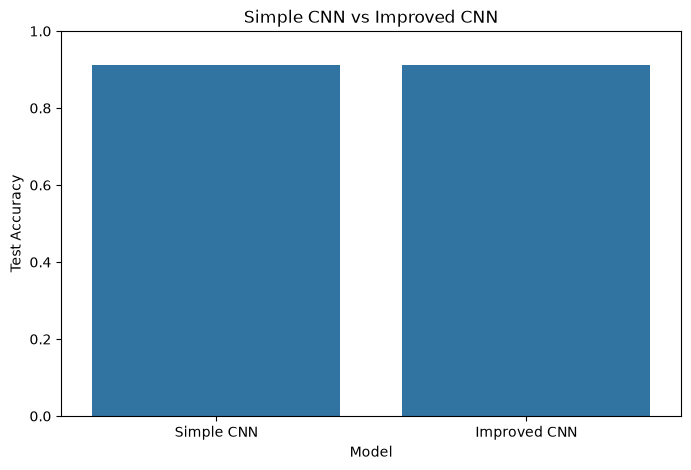

In [62]:
plt.figure(figsize=(8, 5))

sns.barplot(

    data=cnn_comparison,

    x="Model",

    y="Test Accuracy"

)

plt.title("Simple CNN vs Improved CNN")

plt.ylabel("Test Accuracy")

plt.ylim(0, 1)

plt.show()

In [63]:
simple_best_epoch = np.argmax(
    simple_history["val_accuracy"]
) + 1

improved_best_epoch = np.argmax(
    improved_history["val_accuracy"]
) + 1

print("Simple CNN best validation epoch:", simple_best_epoch)

print("Improved CNN best validation epoch:", improved_best_epoch)

print("Simple CNN best validation accuracy:", max(simple_history["val_accuracy"]))

print("Improved CNN best validation accuracy:", max(improved_history["val_accuracy"]))

Simple CNN best validation epoch: 12
Improved CNN best validation epoch: 20
Simple CNN best validation accuracy: 0.9176666666666666
Improved CNN best validation accuracy: 0.9155


In [64]:
simple_best_val = max(
    simple_history["val_accuracy"]
)

improved_best_val = max(
    improved_history["val_accuracy"]
)

if improved_best_val >= simple_best_val:

    best_cnn = improved_model

    best_cnn_name = "Improved CNN"

else:

    best_cnn = simple_model

    best_cnn_name = "Simple CNN"


print("Selected CNN:", best_cnn_name)

print("Simple CNN best validation accuracy:", simple_best_val)

print("Improved CNN best validation accuracy:", improved_best_val)

Selected CNN: Simple CNN
Simple CNN best validation accuracy: 0.9176666666666666
Improved CNN best validation accuracy: 0.9155


In [65]:
first_layer_filters = best_cnn.conv1.weight.detach().cpu().numpy()

print("Filter shape:", first_layer_filters.shape)

print("Number of filters:", first_layer_filters.shape[0])

Filter shape: (32, 1, 3, 3)
Number of filters: 32


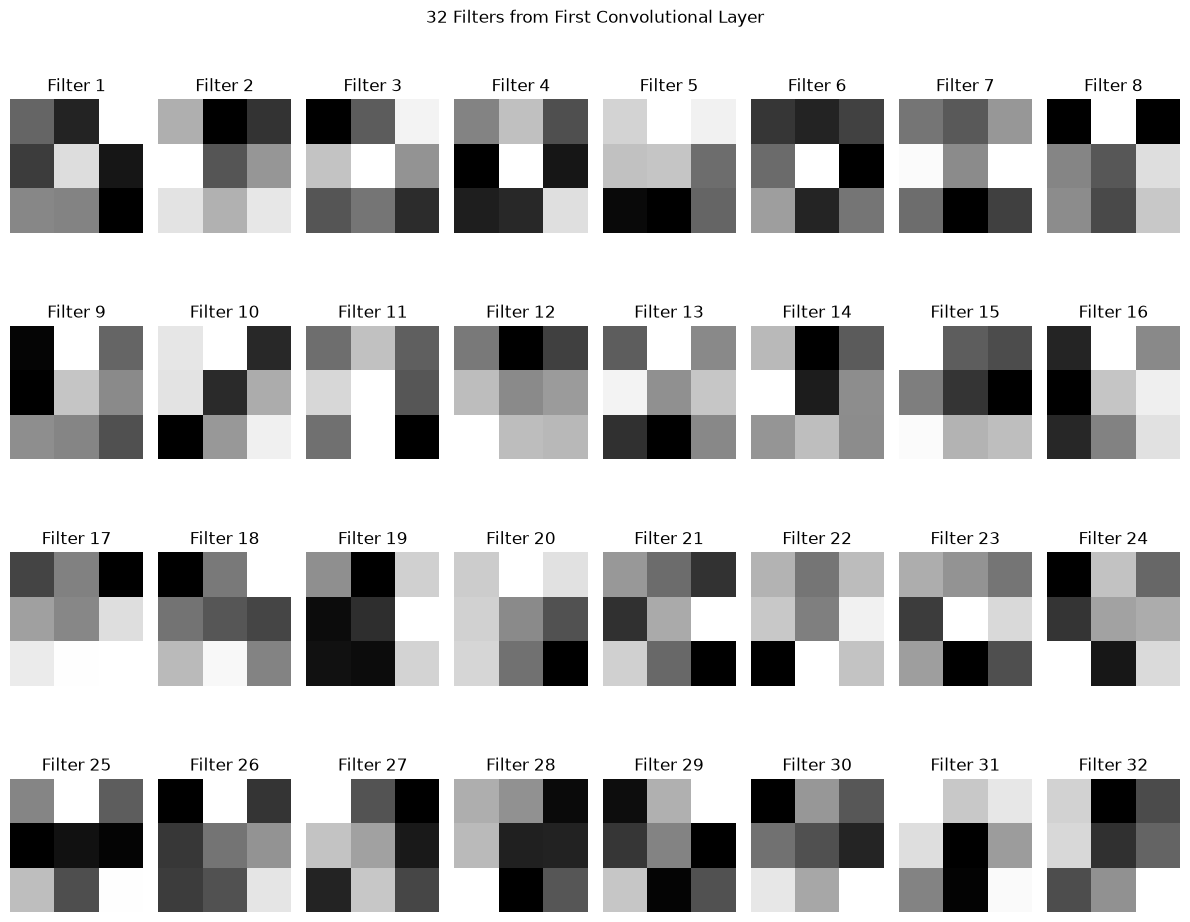

In [66]:
plt.figure(figsize=(12, 10))

for i in range(32):

    filter_image = first_layer_filters[i, 0]

    plt.subplot(4, 8, i + 1)

    plt.imshow(
        filter_image,
        cmap="gray"
    )

    plt.title("Filter " + str(i + 1))

    plt.axis("off")

plt.suptitle("32 Filters from First Convolutional Layer")

plt.tight_layout()

plt.show()

In [67]:
sample_image, sample_label = test_dataset[0]

sample_input = sample_image.unsqueeze(0).to(device)

print("Sample image shape:", sample_image.shape)

print("Sample category:", class_names[sample_label])

Sample image shape: torch.Size([1, 28, 28])
Sample category: Ankle Boot


In [68]:
best_cnn.eval()

with torch.no_grad():

    first_conv_output = best_cnn.conv1(sample_input)

    first_relu_output = best_cnn.relu(first_conv_output)

print("Feature map shape:", first_relu_output.shape)

Feature map shape: torch.Size([1, 32, 26, 26])


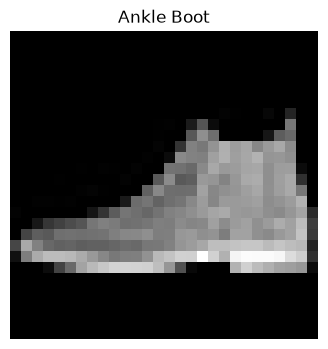

In [69]:
plt.figure(figsize=(4, 4))

plt.imshow(
    sample_image.squeeze(),
    cmap="gray"
)

plt.title(class_names[sample_label])

plt.axis("off")

plt.show()

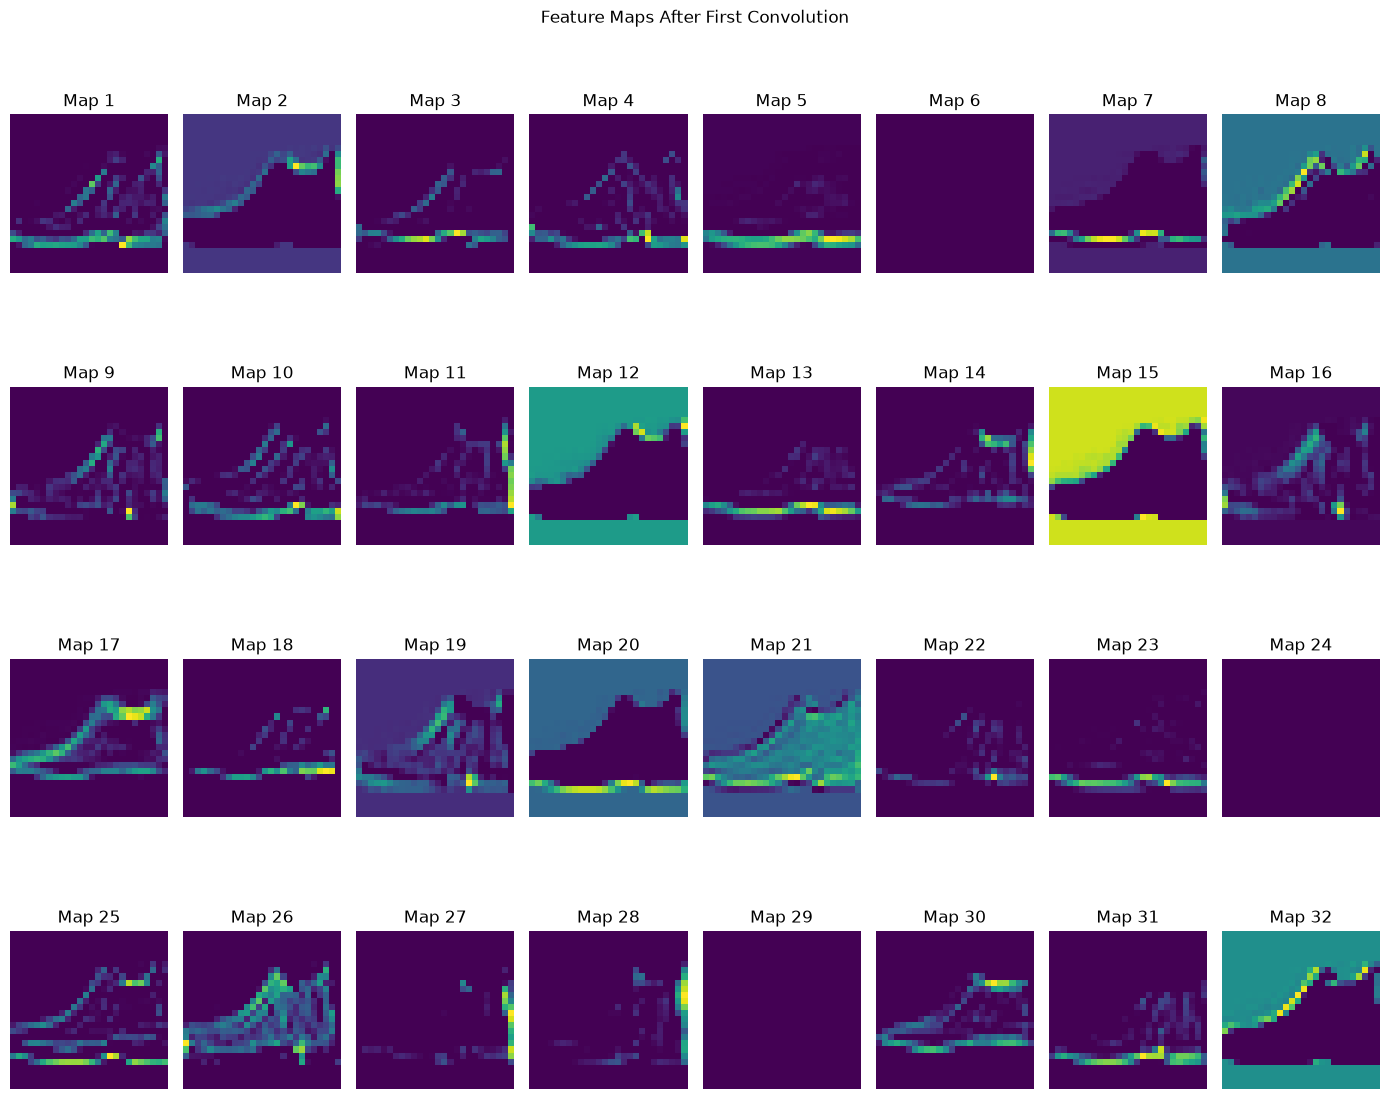

In [70]:
feature_maps = first_relu_output.squeeze(0).cpu().numpy()

plt.figure(figsize=(14, 12))

for i in range(32):

    plt.subplot(4, 8, i + 1)

    plt.imshow(
        feature_maps[i],
        cmap="viridis"
    )

    plt.title("Map " + str(i + 1))

    plt.axis("off")

plt.suptitle("Feature Maps After First Convolution")

plt.tight_layout()

plt.show()

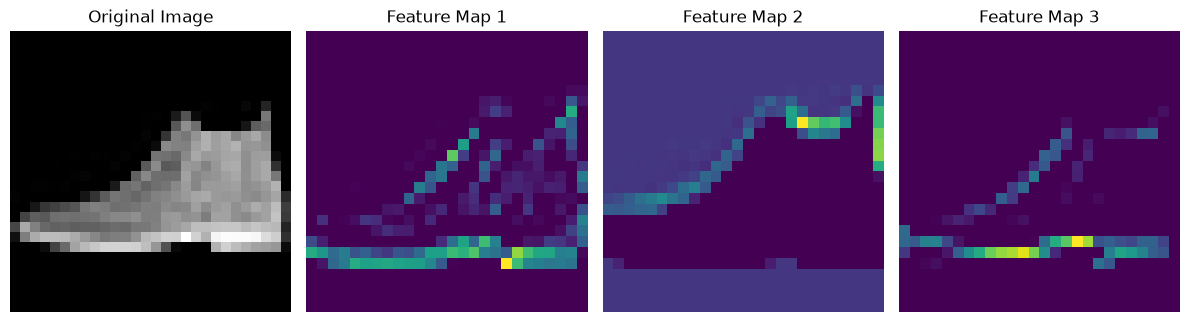

In [71]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 4, 1)

plt.imshow(
    sample_image.squeeze(),
    cmap="gray"
)

plt.title("Original Image")

plt.axis("off")


for i in range(3):

    plt.subplot(1, 4, i + 2)

    plt.imshow(
        feature_maps[i],
        cmap="viridis"
    )

    plt.title("Feature Map " + str(i + 1))

    plt.axis("off")


plt.tight_layout()

plt.show()

In [72]:
layer_summary = []

for name, layer in best_cnn.named_children():

    parameters = sum(

        parameter.numel()

        for parameter in layer.parameters()

    )

    trainable_parameters = sum(

        parameter.numel()

        for parameter in layer.parameters()

        if parameter.requires_grad

    )

    layer_summary.append({

        "Layer": name,

        "Layer Type": layer.__class__.__name__,

        "Parameters": parameters,

        "Trainable Parameters": trainable_parameters

    })


summary_df = pd.DataFrame(layer_summary)

summary_df

,Layer,Layer Type,Parameters,Trainable Parameters
0,conv1,Conv2d,320,320
1,relu,ReLU,0,0
2,pool,MaxPool2d,0,0
3,conv2,Conv2d,18496,18496
4,flatten,Flatten,0,0
5,fc1,Linear,204928,204928
6,fc2,Linear,1290,1290


In [73]:
total_parameters = sum(

    parameter.numel()

    for parameter in best_cnn.parameters()

)

trainable_parameters = sum(

    parameter.numel()

    for parameter in best_cnn.parameters()

    if parameter.requires_grad

)

print("Total parameters:", total_parameters)

print("Trainable parameters:", trainable_parameters)

Total parameters: 225034
Trainable parameters: 225034


In [74]:
best_cnn.eval()

all_predictions = []

all_actual_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = best_cnn(images)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_actual_labels.extend(
            labels.numpy()
        )


print("Total predictions:", len(all_predictions))

print("Total actual labels:", len(all_actual_labels))

Total predictions: 10000
Total actual labels: 10000


In [75]:
correct_predictions = np.sum(

    np.array(all_predictions) == np.array(all_actual_labels)

)

total_predictions = len(all_actual_labels)

overall_accuracy = correct_predictions / total_predictions

print("Correct predictions:", correct_predictions)

print("Total predictions:", total_predictions)

print("Overall Test Accuracy:", overall_accuracy)

Correct predictions: 9128
Total predictions: 10000
Overall Test Accuracy: 0.9128


In [76]:
class_correct = np.zeros(10)

class_total = np.zeros(10)

for actual, predicted in zip(

    all_actual_labels,

    all_predictions

):

    class_total[actual] += 1

    if actual == predicted:

        class_correct[actual] += 1


class_accuracy = (

    class_correct / class_total

) * 100


per_class_results = pd.DataFrame({

    "Class": class_names,

    "Correct Predictions": class_correct.astype(int),

    "Total Images": class_total.astype(int),

    "Accuracy Percentage": class_accuracy

})

per_class_results

,Class,Correct Predictions,Total Images,Accuracy Percentage
0,T-shirt/Top,887,1000,88.7
1,Trouser,975,1000,97.5
2,Pullover,851,1000,85.1
3,Dress,905,1000,90.5
4,Coat,882,1000,88.2
5,Sandal,981,1000,98.1
6,Shirt,738,1000,73.8
7,Sneaker,971,1000,97.1
8,Bag,987,1000,98.7
9,Ankle Boot,951,1000,95.1


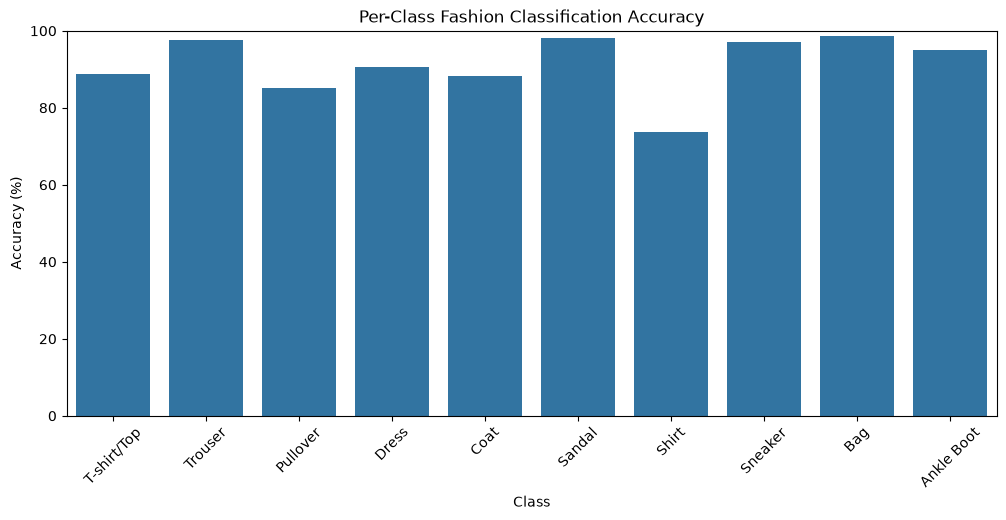

In [77]:
plt.figure(figsize=(12, 5))

sns.barplot(

    data=per_class_results,

    x="Class",

    y="Accuracy Percentage"

)

plt.title("Per-Class Fashion Classification Accuracy")

plt.ylabel("Accuracy (%)")

plt.xticks(rotation=45)

plt.ylim(0, 100)

plt.show()

In [78]:
easiest_class = per_class_results.loc[

    per_class_results["Accuracy Percentage"].idxmax()

]

hardest_class = per_class_results.loc[

    per_class_results["Accuracy Percentage"].idxmin()

]


print("Easiest Class:", easiest_class["Class"])

print("Accuracy:", easiest_class["Accuracy Percentage"])


print("\nHardest Class:", hardest_class["Class"])

print("Accuracy:", hardest_class["Accuracy Percentage"])

Easiest Class: Bag
Accuracy: 98.7

Hardest Class: Shirt
Accuracy: 73.8


In [79]:
cm = confusion_matrix(

    all_actual_labels,

    all_predictions

)

print(cm)

[[887   1  14  14   4   0  72   0   6   2]
 [  3 975   1  11   3   0   4   0   3   0]
 [ 32   0 851   8  41   0  67   0   1   0]
 [ 22   2   7 905  28   1  32   0   2   1]
 [  3   1  40  19 882   0  52   0   3   0]
 [  0   0   0   0   0 981   0  12   1   6]
 [113   3  54  19  67   0 738   0   6   0]
 [  0   0   0   0   0  11   0 971   0  18]
 [  4   0   0   0   3   2   3   1 987   0]
 [  0   0   0   0   0   5   0  43   1 951]]


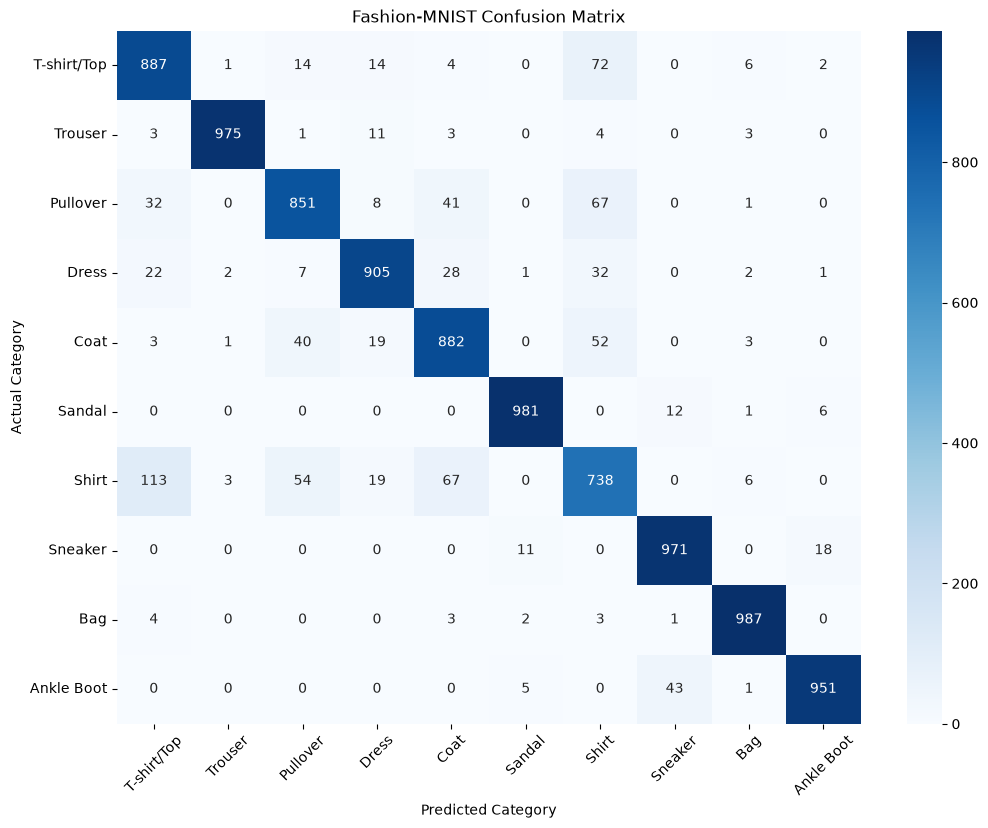

In [80]:
plt.figure(figsize=(12, 9))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=class_names,

    yticklabels=class_names

)

plt.title("Fashion-MNIST Confusion Matrix")

plt.xlabel("Predicted Category")

plt.ylabel("Actual Category")

plt.xticks(rotation=45)

plt.yticks(rotation=0)

plt.show()

In [81]:
confused_pairs = []

for i in range(10):

    for j in range(10):

        if i != j:

            confused_pairs.append({

                "Actual Class": class_names[i],

                "Predicted Class": class_names[j],

                "Wrong Predictions": cm[i, j]

            })


confused_df = pd.DataFrame(confused_pairs)

confused_df = confused_df.sort_values(

    by="Wrong Predictions",

    ascending=False

)

confused_df.head(10)

,Actual Class,Predicted Class,Wrong Predictions
54,Shirt,T-shirt/Top,113
5,T-shirt/Top,Shirt,72
58,Shirt,Coat,67
23,Pullover,Shirt,67
56,Shirt,Pullover,54
41,Coat,Shirt,52
88,Ankle Boot,Sneaker,43
21,Pullover,Coat,41
38,Coat,Pullover,40
18,Pullover,T-shirt/Top,32


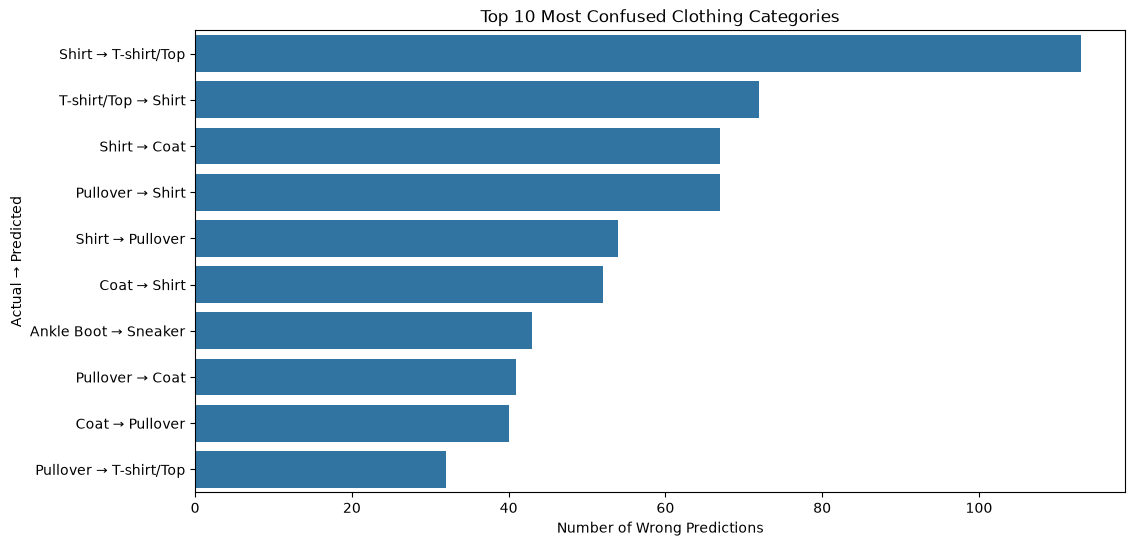

In [82]:
top_confused = confused_df.head(10).copy()

top_confused["Pair"] = (

    top_confused["Actual Class"]

    + " → "

    + top_confused["Predicted Class"]

)

plt.figure(figsize=(12, 6))

sns.barplot(

    data=top_confused,

    x="Wrong Predictions",

    y="Pair"

)

plt.title("Top 10 Most Confused Clothing Categories")

plt.xlabel("Number of Wrong Predictions")

plt.ylabel("Actual → Predicted")

plt.show()

In [83]:
print(

    classification_report(

        all_actual_labels,

        all_predictions,

        target_names=class_names

    )

)

              precision    recall  f1-score   support

 T-shirt/Top       0.83      0.89      0.86      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.88      0.85      0.87      1000
       Dress       0.93      0.91      0.92      1000
        Coat       0.86      0.88      0.87      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.76      0.74      0.75      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.98      0.99      0.98      1000
  Ankle Boot       0.97      0.95      0.96      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



In [84]:
misclassified_images = []

for i in range(len(all_actual_labels)):

    if all_actual_labels[i] != all_predictions[i]:

        misclassified_images.append(i)


print("Number of misclassified images:", len(misclassified_images))

Number of misclassified images: 872


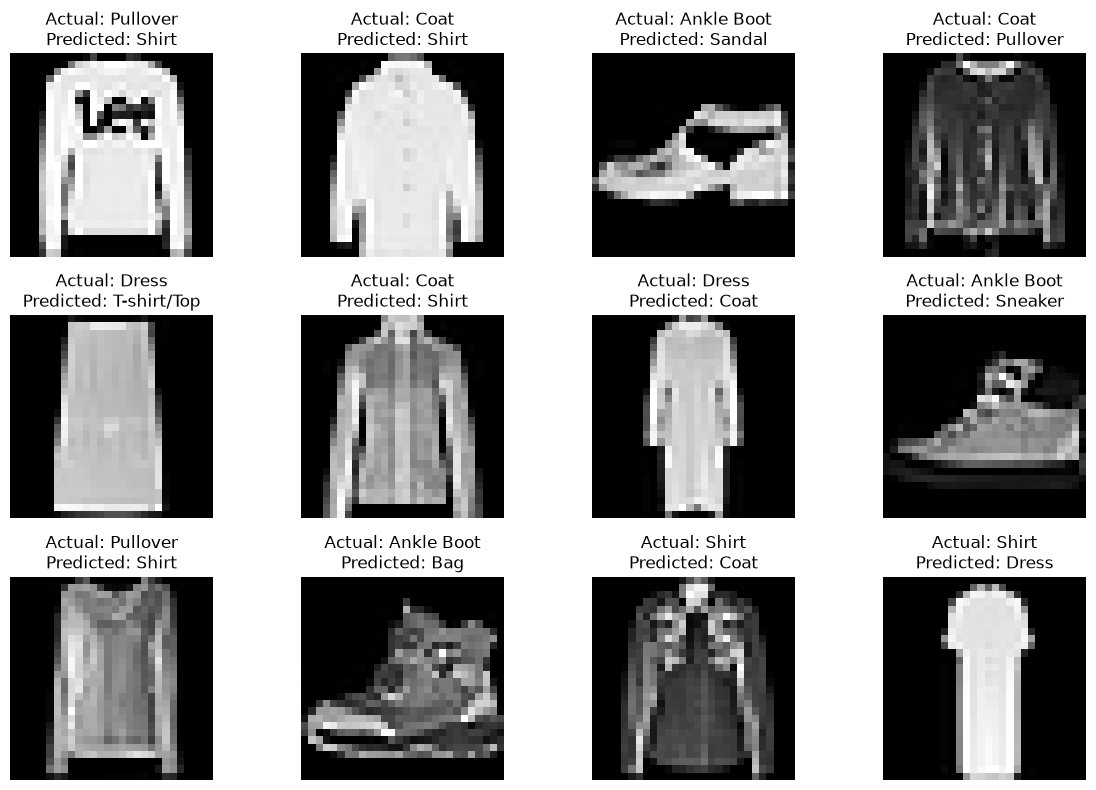

In [85]:
plt.figure(figsize=(12, 8))

for i in range(12):

    image_index = misclassified_images[i]

    image, actual_label = test_dataset[image_index]

    predicted_label = all_predictions[image_index]

    plt.subplot(3, 4, i + 1)

    plt.imshow(

        image.squeeze(),

        cmap="gray"

    )

    plt.title(

        "Actual: " + class_names[actual_label]

        + "\nPredicted: " + class_names[predicted_label]

    )

    plt.axis("off")


plt.tight_layout()

plt.show()

In [86]:
class FashionMLP(nn.Module):

    def __init__(self):

        super(FashionMLP, self).__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(

            784,

            128

        )

        self.relu = nn.ReLU()

        self.fc2 = nn.Linear(

            128,

            64

        )

        self.fc3 = nn.Linear(

            64,

            10

        )


    def forward(self, x):

        x = self.flatten(x)

        x = self.fc1(x)

        x = self.relu(x)

        x = self.fc2(x)

        x = self.relu(x)

        x = self.fc3(x)

        return x

In [87]:
mlp_model = FashionMLP()

mlp_model = mlp_model.to(device)

mlp_criterion = nn.CrossEntropyLoss()

mlp_optimizer = optim.Adam(

    mlp_model.parameters(),

    lr=0.001

)

print(mlp_model)

FashionMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)


In [88]:
mlp_history = {

    "train_loss": [],

    "val_loss": [],

    "train_accuracy": [],

    "val_accuracy": []

}

for epoch in range(15):

    train_loss, train_accuracy = train_one_epoch(

        mlp_model,

        train_loader,

        mlp_criterion,

        mlp_optimizer

    )

    val_loss, val_accuracy = evaluate_model(

        mlp_model,

        val_loader,

        mlp_criterion

    )

    mlp_history["train_loss"].append(train_loss)

    mlp_history["val_loss"].append(val_loss)

    mlp_history["train_accuracy"].append(train_accuracy)

    mlp_history["val_accuracy"].append(val_accuracy)

    print(

        f"Epoch {epoch + 1}/15 | "

        f"Train Accuracy: {train_accuracy:.4f} | "

        f"Validation Accuracy: {val_accuracy:.4f}"

    )

Epoch 1/15 | Train Accuracy: 0.7998 | Validation Accuracy: 0.8282
Epoch 2/15 | Train Accuracy: 0.8567 | Validation Accuracy: 0.8588
Epoch 3/15 | Train Accuracy: 0.8701 | Validation Accuracy: 0.8695
Epoch 4/15 | Train Accuracy: 0.8787 | Validation Accuracy: 0.8707
Epoch 5/15 | Train Accuracy: 0.8851 | Validation Accuracy: 0.8770
Epoch 6/15 | Train Accuracy: 0.8907 | Validation Accuracy: 0.8765
Epoch 7/15 | Train Accuracy: 0.8953 | Validation Accuracy: 0.8802
Epoch 8/15 | Train Accuracy: 0.9005 | Validation Accuracy: 0.8810
Epoch 9/15 | Train Accuracy: 0.9010 | Validation Accuracy: 0.8797
Epoch 10/15 | Train Accuracy: 0.9061 | Validation Accuracy: 0.8812
Epoch 11/15 | Train Accuracy: 0.9082 | Validation Accuracy: 0.8868
Epoch 12/15 | Train Accuracy: 0.9110 | Validation Accuracy: 0.8815
Epoch 13/15 | Train Accuracy: 0.9146 | Validation Accuracy: 0.8833
Epoch 14/15 | Train Accuracy: 0.9171 | Validation Accuracy: 0.8865
Epoch 15/15 | Train Accuracy: 0.9201 | Validation Accuracy: 0.8898


In [89]:
mlp_test_loss, mlp_test_accuracy = evaluate_model(

    mlp_model,

    test_loader,

    mlp_criterion

)

print("MLP Test Loss:", mlp_test_loss)

print("MLP Test Accuracy:", mlp_test_accuracy)

MLP Test Loss: 0.3452421890258789
MLP Test Accuracy: 0.8833


In [90]:
best_cnn_test_loss, best_cnn_test_accuracy = evaluate_model(

    best_cnn,

    test_loader,

    nn.CrossEntropyLoss()

)

final_comparison = pd.DataFrame({

    "Model": [

        "MLP",

        "Simple CNN",

        "Improved CNN",

        "Best CNN"

    ],

    "Test Accuracy": [

        mlp_test_accuracy,

        simple_test_accuracy,

        improved_test_accuracy,

        best_cnn_test_accuracy

    ],

    "Test Loss": [

        mlp_test_loss,

        simple_test_loss,

        improved_test_loss,

        best_cnn_test_loss

    ]

})

final_comparison

,Model,Test Accuracy,Test Loss
0,MLP,0.8833,0.345242
1,Simple CNN,0.9128,0.451818
2,Improved CNN,0.9115,0.245053
3,Best CNN,0.9128,0.451818


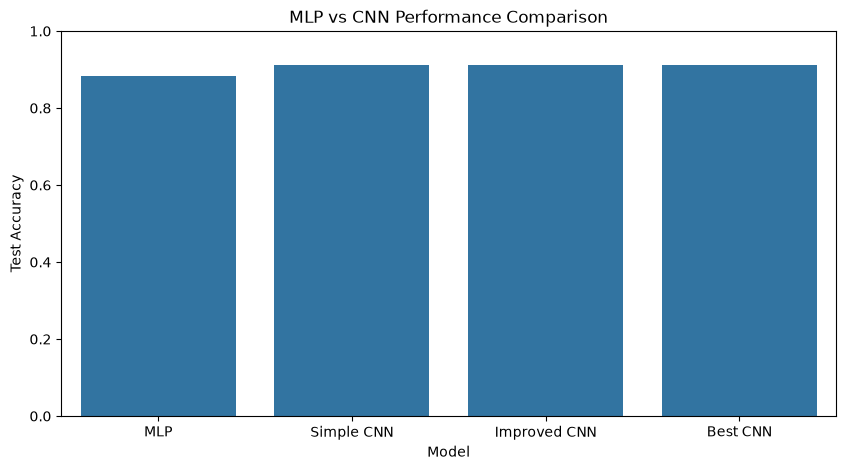

In [91]:
plt.figure(figsize=(10, 5))

sns.barplot(

    data=final_comparison,

    x="Model",

    y="Test Accuracy"

)

plt.title("MLP vs CNN Performance Comparison")

plt.xlabel("Model")

plt.ylabel("Test Accuracy")

plt.ylim(0, 1)

plt.show()

In [92]:
best_overall_model = final_comparison.loc[

    final_comparison["Test Accuracy"].idxmax(),

    "Model"

]

best_overall_accuracy = final_comparison["Test Accuracy"].max()

print("Best Performing Model:", best_overall_model)

print("Test Accuracy:", best_overall_accuracy)

Best Performing Model: Simple CNN
Test Accuracy: 0.9128


In [93]:
torch.save(

    best_cnn.state_dict(),

    "fashion_best_cnn.pth"

)

print("Best CNN model saved successfully!")

Best CNN model saved successfully!


In [94]:
torch.save(

    mlp_model.state_dict(),

    "fashion_mlp_final.pth"

)

print("MLP model saved successfully!")

MLP model saved successfully!


In [95]:
final_comparison.to_csv(

    "fashion_model_comparison.csv",

    index=False

)

per_class_results.to_csv(

    "fashion_per_class_accuracy.csv",

    index=False

)

confused_df.to_csv(

    "fashion_confused_pairs.csv",

    index=False

)

print("All comparison results saved!")

All comparison results saved!


In [96]:
np.save(

    "fashion_cnn_first_layer_filters.npy",

    first_layer_filters

)

np.save(

    "fashion_cnn_feature_maps.npy",

    feature_maps

)

print("CNN filters and feature maps saved!")

CNN filters and feature maps saved!


In [97]:


print("\nDataset Information")

print("Training Images:", len(train_subset))

print("Validation Images:", len(val_subset))

print("Testing Images:", len(test_dataset))

print("Number of Classes:", len(class_names))


print("\nModel Results")

print(final_comparison)


print("\nSelected CNN:", best_cnn_name)

print("Best CNN Test Accuracy:", best_cnn_test_accuracy)


print("\nHardest Clothing Category:")

print(hardest_class["Class"])

print("Accuracy:", hardest_class["Accuracy Percentage"])


print("\nEasiest Clothing Category:")

print(easiest_class["Class"])

print("Accuracy:", easiest_class["Accuracy Percentage"])


print("\nTop 5 Confused Clothing Pairs")

print(confused_df.head(5))


print("\nAssignment Completed Successfully!")



Dataset Information
Training Images: 54000
Validation Images: 6000
Testing Images: 10000
Number of Classes: 10

Model Results
          Model  Test Accuracy  Test Loss
0           MLP         0.8833   0.345242
1    Simple CNN         0.9128   0.451818
2  Improved CNN         0.9115   0.245053
3      Best CNN         0.9128   0.451818

Selected CNN: Simple CNN
Best CNN Test Accuracy: 0.9128

Hardest Clothing Category:
Shirt
Accuracy: 73.8

Easiest Clothing Category:
Bag
Accuracy: 98.7

Top 5 Confused Clothing Pairs
   Actual Class Predicted Class  Wrong Predictions
54        Shirt     T-shirt/Top                113
5   T-shirt/Top           Shirt                 72
58        Shirt            Coat                 67
23     Pullover           Shirt                 67
56        Shirt        Pullover                 54

Assignment Completed Successfully!
